## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "" # @param {"type":"string"}
carnet = None # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**
1. Una empresa debe administrar tareas técnicas según su prioridad y conectar
varios dispositivos utilizando la menor cantidad total de cable.<br>
Código->Tarea->Prioridad<br>
T01 ->Configurar servidor ->6<br>
T02 ->Reparar sensor ->10<br>
T03 ->Actualizar software ->4<br>
T04 ->Revisar cámara ->8<br>
T05 ->Generar respaldo ->3<br>
T06 ->Configurar alarma ->7




## 2) Requerimientos **[2 pts]**

###REQUERIMIENTOS FUNCIONALES

RQF01: REGISTRO DE LAS TAREAS- EL porgrama declara las tareas junto a sus prioridades

RQF02: CONSTRUCCION DEL MAX-HEAP- A partir de las tareas ingresadas, el programa debe organizar los datos en forma de Max-Heap utilizando las funciones manuales MAX-HEAPIFY y BUILD-MAX-HEAP. Esto debe asegurar que cualquier tarea en el árbol tenga una prioridad mayor o igual que la de sus hijos.

RQF03: IMPLEMENTAR EXTRACT-MAX- El programa debe poder procesar las dos tareas con mayor prioridad

RQF04: AGREGAR TAREA- Posteriormente agregue la siguiente tarea y mantenga la propiedad del Max-Heap: T07 - Falla en sistema contra incendios - Prioridad 12


RQF05: IMPLEMENTAR KRUSKAL- Implemente manualmente el algoritmo de Kruskal para conectar los seis dispositivos.
DDYA 2026-2
Parcial práctico - Colas de prioridad y árbol de expansión mínima | Página 2
1. Ordene las aristas por peso.
2. Seleccione las conexiones de menor costo.
3. Evite ciclos.
4. Deténgase cuando los seis dispositivos estén conectados.

RQF06: GRAFICART- Genere una gráfica final que muestre:
1. Los seis dispositivos.
2. Únicamente las conexiones del MST.
3. El peso de cada conexión.
4. La longitud total de cable utilizada.


###REQUERIMIENTOS NO FUNCIONALES

RQNF01: Eficiencia- El programa debe realizar las operaciones de los árboles de forma eficiente.

RQNF02:Mantenibilidad- El código debe estar organizado y ser fácil de modificar.

RQNF03:Corrección- El programa debe construir correctamente el Max-Heap y la cola de prioridad, asegurando que se cumpla la propiedad de Max-Heap en todas las operaciones (registro, extracción e inserción) sin utilizar la librería.

RQNF04:Lenguaje- El programa se desarrollará en Python por su facilidad de uso y por permitir implementar y visualizar los árboles de forma sencilla.



## 3) Historias de usuario **[2 pts]**
HU1, registrar las tareas:
las guarda como diccionarios en orden de ingreso.

HU2, construir el Max-Heap
valida que haya tareas, construye el max heap y muestra el heap como lista

HU3, implementar extract max
se utiliza extract max para obtener las dos tareas de mayor prioridad.

HU4, implementar kruskal:
utilizar el algoritmo de kruskal para hallar la ruta menos pesada

HU5, graficas
poder mostrar el el max heap graficamete.

## 4) Diagramas de flujo **[5 pts]**
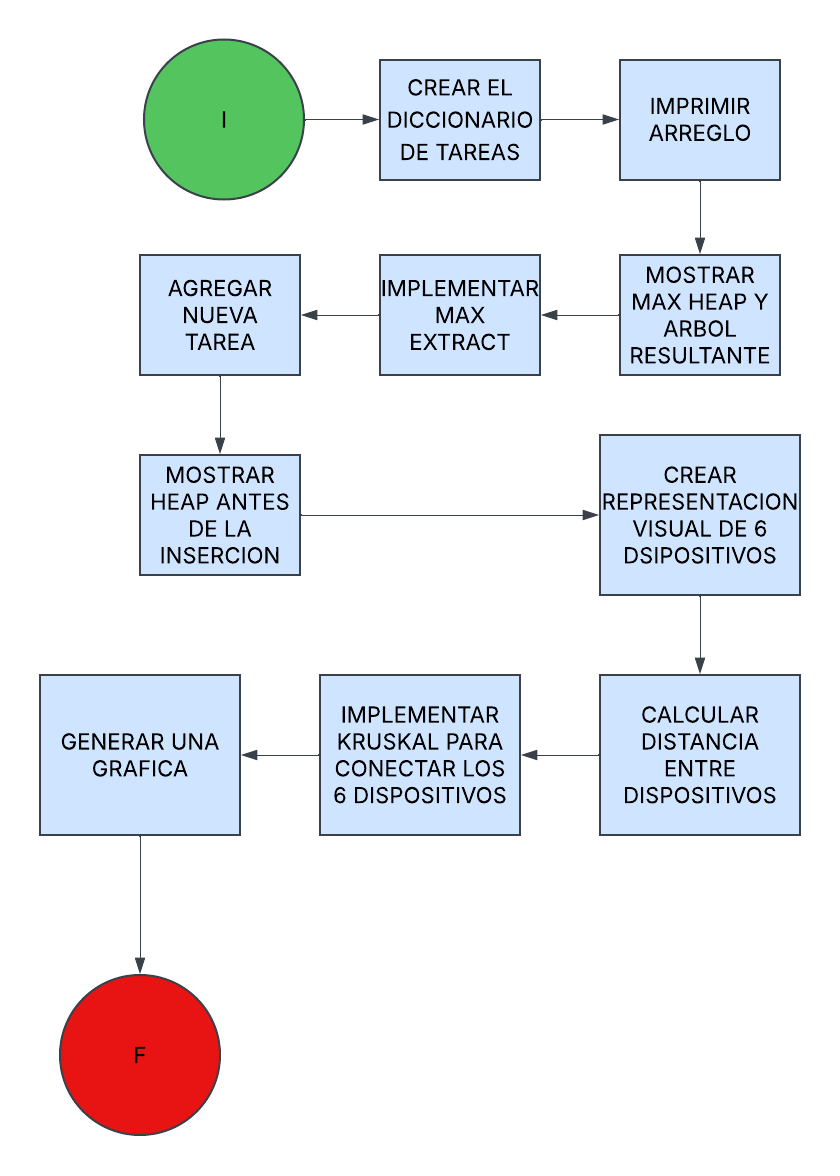
En este diagram de flujo se evidencia claramente el proceso para resolveer cada porblema, utilizando los algoritmos y diseño de datos correspondiente


### 5) Análisis de complejidad **[15 pts]**
Mejor caso: O(1) para consultas (MAXIMUM) o cuando un elemento insertado ya cumple con la propiedad del montículo y no requiere ningún desplazamiento en el árbol.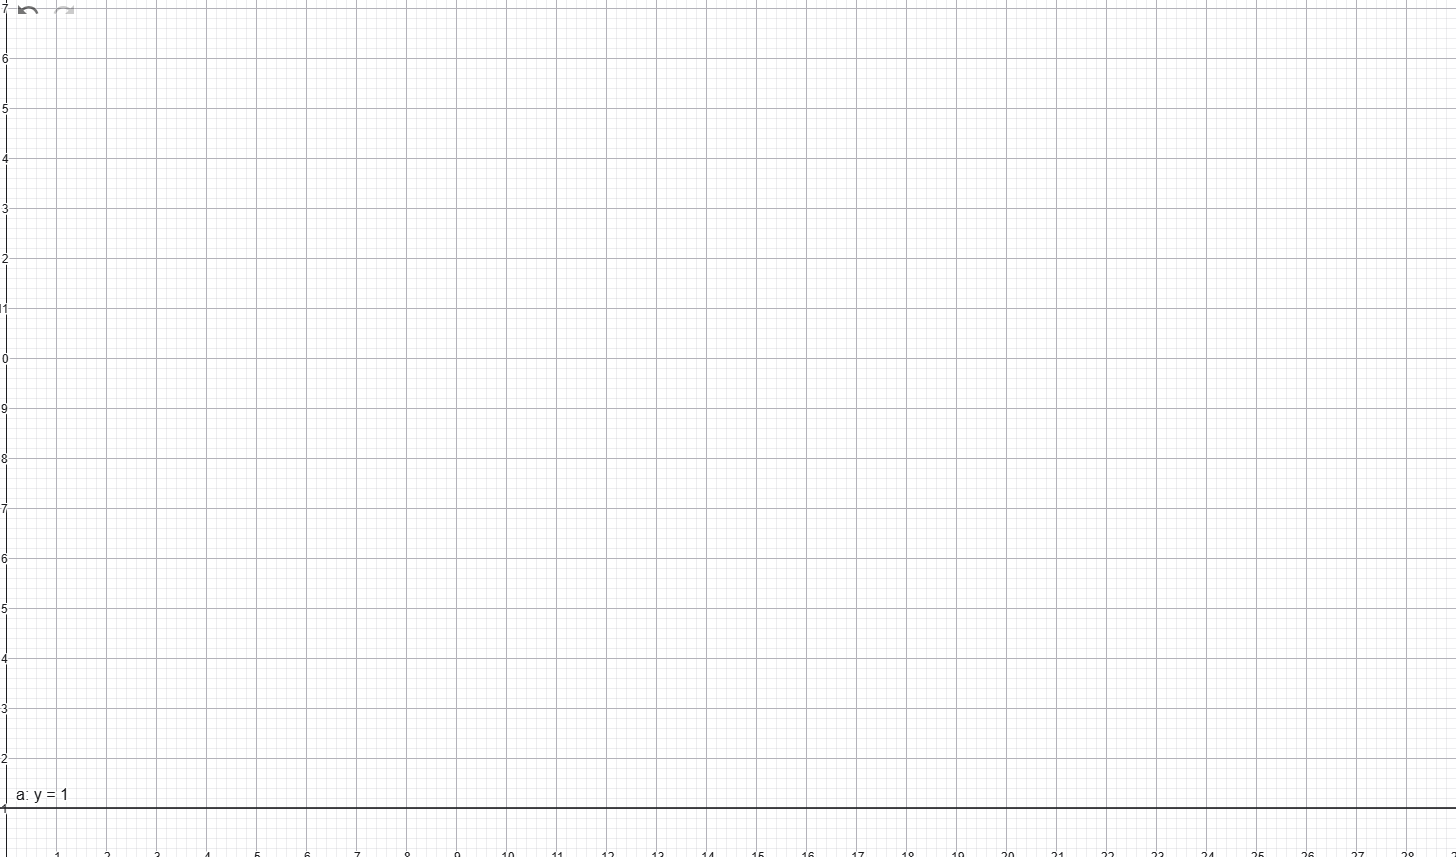
Peor caso: O(\log n) para inserciones, extracciones y heapify cuando un elemento debe recorrer toda la altura del árbol y O(n \log n) para el orden completo (HEAPSORT).
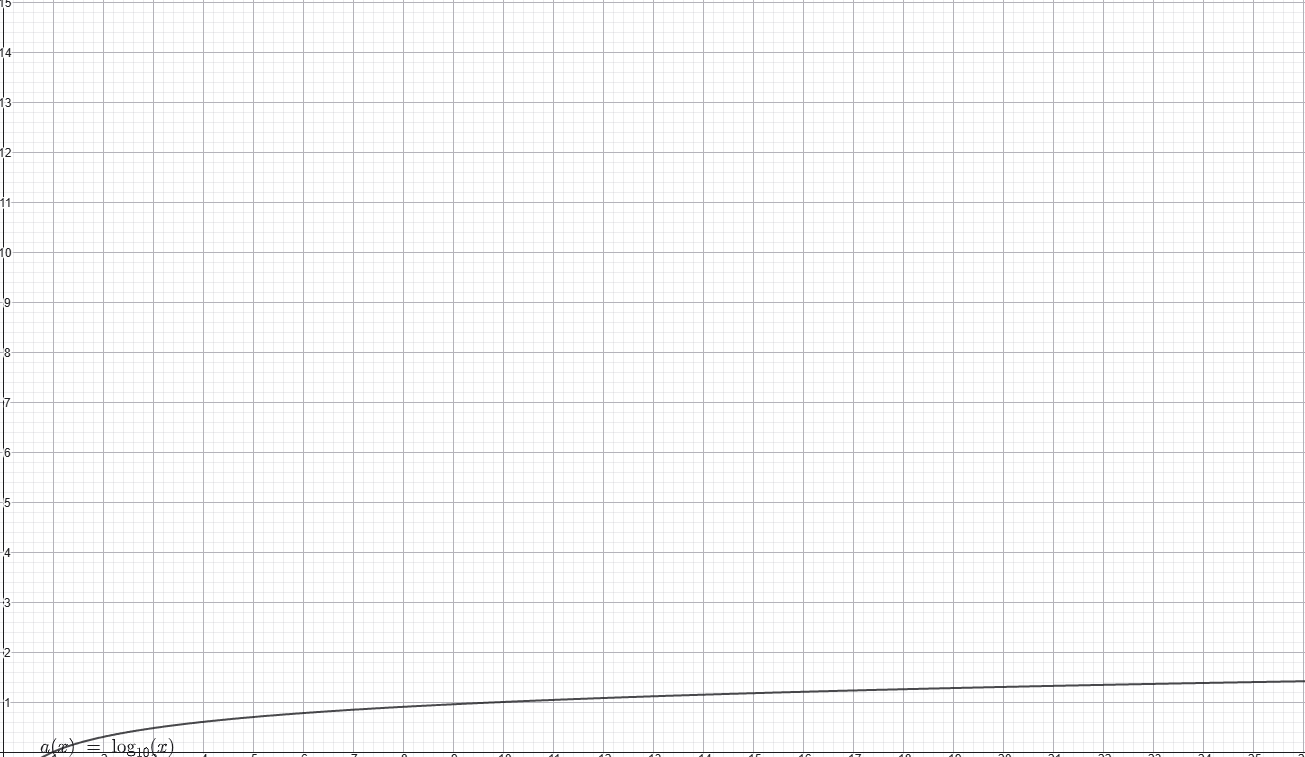

## 6) Código funcional **[15 pts]**
Incluye tu implementación completa.

No pegues código incompleto; debe ser ejecutable.


In [ ]:
#PUNTO 1 Y 2

from math import sqrt


def padre(i):
    return (i - 1) // 2
def izq(i):
    return 2 * i + 1
def der(i):
    return 2 * i + 2

def max_heapify(arr, n, i):
   mayor = i
   izq = 2 * i + 1
   der = 2 * i + 2
   if izq < n and arr[izq]["prior"] > arr[mayor]["prior"]:
       mayor = izq
   if der < n and arr[der]["prior"] > arr[mayor]["prior"]:
       mayor = der
   if mayor != i:
       arr[i], arr[mayor] = arr[mayor], arr[i]
       max_heapify(arr, n, mayor)

def heap_constr(tareas):
    tamaño = len(tareas)
    for i in range(tamaño // (2 - 1), -1, -1):
        max_heap(tareas,i,tamaño)

def max_heap(tareas, i, tamaño):
    iz = izq(i)
    de = der(i)
    a = i
    if (iz < tamaño) and (tareas[iz]["prior"] > tareas[a]["prior"]):
        a = iz
    if (de < tamaño) and (tareas[de]["prior"] > tareas[a]["prior"]):
        a = de
    if a != i:
        tareas[i], tareas[a] = tareas[a], tareas[i]
        max_heap(tareas, a, tamaño)

def extract_max(tareas):
    print(tareas)

def punt_maxheap():
    tareas = [{"cod": "T01", "tarea": "Configurar servidor", "prior": 6},
            {"cod": "T02", "tarea": "Reparar sensor", "prior": 10},
            {"cod": "T03", "tarea": "Actualizar software", "prior": 4},
            {"cod": "T04", "tarea": "Revisar cámara", "prior": 8},
            {"cod": "T05", "tarea": "Generar respaldo", "prior": 3},
            {"cod": "T06", "tarea": "Configurar alarma", "prior": 7}]
    print("arreglo inicial")
    for c in (tareas):
        print(c)
    heap_constr(tareas)
    print("Max-Heap:", [t["prior"] for t in tareas])
    extract_max(tareas)
    nuev_tarea = [{"cod": "T07", "tarea": "Falla en sistema contra incendios", "prior": 12}]
    tareas.append(nuev_tarea)
    #heap_constr(tareas)
    #print("Max-Heap:", [t["prior"] for t in tareas])
punt_maxheap()


#PUNTO 3,4 y 5


def punt_kruskal():
    dispositivos = [{"disp": "servidor", "id": "A", "x": 2, "y":2},
                    {"disp": "camara", "id": "B", "x": 7, "y":3},
                    {"disp": "sensor", "id": "C", "x": 4, "y":7},
                    {"disp": "alarma", "id": "D", "x": 10, "y":8},
                    {"disp": "router", "id": "E", "x": 13, "y":3},
                    {"disp": "panel", "id": "F", "x": 15, "y":7},]
    #for x,y in (dispositivos["x"],dispositivos["y"]):
        #distancia = sqrt((x2 - x1)^2 + (y2 - y1)^2)
        #print(distancia)
punt_kruskal()

def kruskal(conexiones, nodos):
   conexiones.sort()
   padre = {nodo: nodo for nodo in nodos}
   mst = []
   longitud_total = 0
   for peso, u, v in conexiones:
       raiz_u = padr(padre, u)
       raiz_v = padr(padre, v)
       if raiz_u != raiz_v:
           mst.append((peso, u, v))
           longitud_total += peso
           unir_nodos(padre, raiz_u, raiz_v)
           if len(mst) == len(nodos) - 1:
               break

def padr(padre, i):
   if padre[i] == i:
       return i
   return padr(padre, padre[i])

## 7) Tests aplicados **[15 pts]**

In [ ]:
# (Opcional) Ejemplo de asserts (ajusta a tu código):
# assert funcion(0) == 0
# assert funcion(1) == 1
# assert funcion(6) == 8
